# 2026 OSS 예제 코드

## 패키지 import

In [10]:
from ultralytics import YOLO
import os
from PIL import Image
import cv2
import matplotlib.pyplot as plt
import cv2
from IPython.display import Image as IPyImage, display

## 데이터셋 및 사전학습 모델 다운로드 & 학습 및 검증

In [2]:
model = YOLO("yolo26n.pt")

In [3]:
results = model.train(data="coco8.yaml", epochs=3)

New https://pypi.org/project/ultralytics/8.4.202 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.200  Python-3.11.18 torch-2.14.1 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosai

In [13]:
results = model.val()

Ultralytics 8.4.200  Python-3.11.18 torch-2.14.1 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
YOLO26n summary (fused): 120 layers, 2,408,932 parameters, 0 gradients, 5.5 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 452.9±141.6 MB/s, size: 54.0 KB)
val: Scanning C:\Users\khb24\Downloads\2026_OSS\datasets\coco8\labels\val.cache... 4 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4/4  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 12.9it/s 0.1s
                   all          4         17      0.546      0.971      0.943      0.681
                person          3         10      0.543      0.833      0.851      0.389
                   dog          1          1      0.356          1      0.995      0.597
                 horse          1          2      0.341          1      0.995      0.696
              elephant          1          2      0.665      0.995      0.828      0.512
              umbrella   

## 테스트

In [15]:
img = Image.open('./datasets/coco8/images/val/000000000061.jpg')
results = model.predict(source=img, save=True)


0: 512x640 1 person, 2 elephants, 81.4ms
Speed: 3.1ms preprocess, 81.4ms inference, 2.2ms postprocess per image at shape (1, 3, 512, 640)
Results saved to C:\Users\khb24\Downloads\2026_OSS\runs\detect\predict-2


## 시각화 함수

In [16]:
def cv2_imshow(img, width=600):
    _, buf = cv2.imencode(".png", img)
    display(IPyImage(data=buf.tobytes(), width=width))

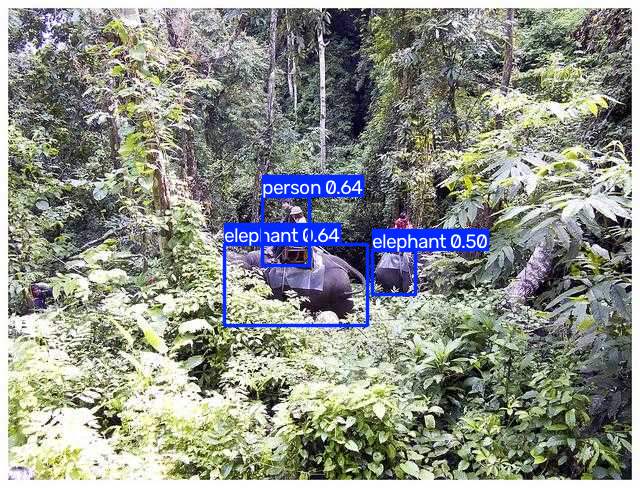

In [17]:
cv2_imshow(results[0].plot())

In [19]:
results[0].boxes

ultralytics.engine.results.Boxes object with attributes:

cls: tensor([ 0., 20., 20.], device='cuda:0')
conf: tensor([0.6419, 0.6376, 0.5022], device='cuda:0')
data: tensor([[262.3156, 196.9277, 309.9644, 265.0396,   0.6419,   0.0000],
        [224.4844, 244.7902, 367.0023, 325.6127,   0.6376,  20.0000],
        [372.8002, 250.9846, 415.2609, 294.5655,   0.5022,  20.0000]], device='cuda:0')
id: None
is_track: False
orig_shape: (488, 640)
shape: torch.Size([3, 6])
xywh: tensor([[286.1400, 230.9836,  47.6488,  68.1119],
        [295.7433, 285.2014, 142.5179,  80.8225],
        [394.0305, 272.7750,  42.4606,  43.5809]], device='cuda:0')
xywhn: tensor([[0.4471, 0.4733, 0.0745, 0.1396],
        [0.4621, 0.5844, 0.2227, 0.1656],
        [0.6157, 0.5590, 0.0663, 0.0893]], device='cuda:0')
xyxy: tensor([[262.3156, 196.9277, 309.9644, 265.0396],
        [224.4844, 244.7902, 367.0023, 325.6127],
        [372.8002, 250.9846, 415.2609, 294.5655]], device='cuda:0')
xyxyn: tensor([[0.4099, 0.4035, 0

## 학습관련된 파일들은 현재경로/rus/detect/train에 저장이 됩니다.

In [5]:
%pwd

'c:\\Users\\khb24\\Downloads\\2026_OSS'

In [19]:
model.trainer.save_dir

WindowsPath('C:/Users/khb24/Downloads/2026_OSS/runs/detect/train-2')

## best모델 가중치로 prediction


image 1/1 c:\Users\khb24\Downloads\2026_OSS\datasets\coco8\images\val\000000000042.jpg: 480x640 1 dog, 1 backpack, 53.7ms
Speed: 2.6ms preprocess, 53.7ms inference, 3.5ms postprocess per image at shape (1, 3, 480, 640)
Results saved to C:\Users\khb24\Downloads\2026_OSS\runs\detect\predict-2


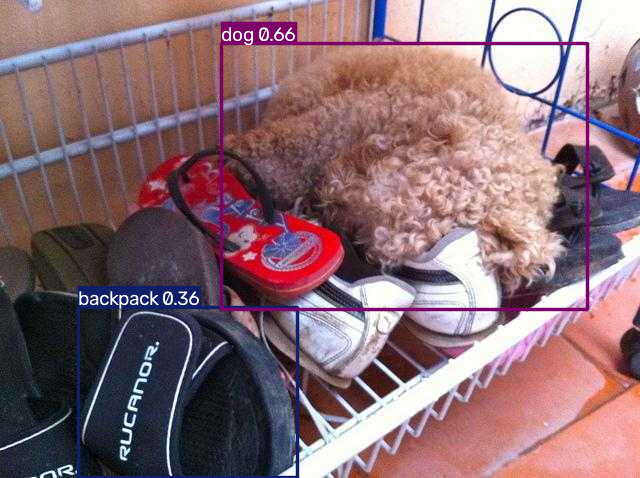

In [21]:
model1 = YOLO(f"{model.trainer.save_dir}/weights/best.pt")
results = model.predict(source='./datasets/coco8/images/val/000000000042.jpg', save=True)
cv2_imshow(results[0].plot())